# Phase II, Pair 1: question E, far from typical weather

*Does the model notice, internally and in its band, when a context is far from typical weather, and how far must it be?*

| | |
|---|---|
| Authors | Sandro Müller K52010874 |
| Status | in progress |
| Phase I result this builds on | Exp 6 (inserting cold drops into the history widens the band, but it shrinks again for the largest drops) and Exp 11 (band honest on normal days); question D (same model state) |

## 1 · Question

Does the model notice, internally and in its band, when a context is far from typical weather, and how far must it be?

"Out of distribution" is made concrete in two ways:

- **Far from typical** = five kinds of injected anomalies at growing size (a flat stretch, spikes, a gap, a unit shift, a
  strange history as in Exp 6), always in the last 72 h of the context.
- **How far** = a distance score: the mean distance from the context's model state to its 10 nearest states of typical
  contexts (section 5). "Far" starts where the score leaves the range of held-out typical contexts.

## 2 · Why this question

In Phase I, a stranger history (Exp 6) made the band wider, but only up to medium drop sizes; for the largest drops it
shrank again. At fronts the band held only 32 % of the hours. So the band is not a reliable
"I am unsure" signal. We want to know whether the model registers unusual input at all (in its state), whether that
reaches the band, and where on the scale from "a bit unusual" to "clearly broken input" this happens.

## 3 · Hypothesis and what would count as an answer

**Hypotheses.** For each type of anomaly we ask three things:

- **H1.** Whether the distance score of the state changes with the size of the anomaly, and from which size on it leaves the typical range.
- **H2.** Whether the band width changes with the size of the anomaly.
- **H3.** Whether, for some types, the error changes with the size of the anomaly while the band does not.

**What would count as an answer.**

- *The state reacts:* the median score of a size is above the 95th percentile of the held-out typical contexts, and the control (size 0) stays inside the typical range.
- *The band reacts:* the band width changes with the size; read from the rank correlation of score and band, and from the paired change against size 0.
- *Error without band:* the error changes with the size while the band width stays about the same. The combinations are read in section 8.0.

The answer is given per anomaly type.

Each hypothesis is tested and answered in its own part of section 8: [H1](#h1) · [H2](#h2) · [H3](#h3).

## 4 · Setup

The code cell below holds the imports, paths and model loading. The model facts are the same as in question D.

### What the source says

*Read in `tirex2.py`, version `tirex-2==0.3.1` (as pinned) and `main`; the same answers as in question D.*

| Point | What we found |
|---|---|
| `input_patch_size`, number of blocks | From the checkpoint config; both are printed below. |
| `_forward_layerwise(self, x, group_vector, target_mask, known_covariate_mask)` | 0.3.1; `main` adds `indices=None`. Yields the tokens after every block. We read the same tensors with forward hooks on `core.stack[b]`. |
| Gradients | `predict` / `forecast` run under `@torch.no_grad`; not needed here. |

### The state

**State = output of the last block at the last context patch**, from `model_state.py`: the same function as in D
(agreed with D).

NaN in the context (the gap anomaly) is allowed. The model masks NaN hours itself, and they are not filled here,
because filling would hide the anomaly.

In [ ]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from model_state import context_token, hidden_states, state_and_forecast
from tirex2 import load_model

# Paths and settings
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = Path(os.environ.get("AIVIS_DATA", ROOT / "data" / "austria_15km"))
CKPT = os.environ.get("TIREX_CKPT", "NX-AI/TiRex-2")  # a local folder works too
DEVICE = os.environ.get("TIREX_DEVICE", "cpu")
RESULTS = ROOT / "data" / "notebooks" / "results" / "05_question_e"
RESULTS.mkdir(parents=True, exist_ok=True)

CONTEXT, HORIZON, SEED = 672, 24, 0  # Phase I design: 28 days of history, 24 h forecast

# Load the model and print the numbers we need to know
model = load_model(CKPT, device=DEVICE)
core = model.model  # the TiRex2 backbone
h = hidden_states(model, np.zeros((1, CONTEXT), np.float32))  # one dummy context, to read the token layout
print(
    f"input_patch_size {core.input_patch_size} | blocks {len(core.stack)} | embedding_dim {core.embedding_dim}"
    f" | state token {context_token(core, h.shape[2])} of {h.shape[2]}"
)

input_patch_size 32 | blocks 12 | embedding_dim 512 | state token 63 of 74


## 5 · Data

**Typical contexts.** Phase I grid starts (672 h context, 24 h horizon, filled as in `run_forecasts.py`) with no cold-front
peak within 48 h of the start, at `N_REF_POINTS` points spread over Austria. Using the Phase I starts lets us check the
unchanged forecasts against `tirex2_forecasts.npz`.

**Held out.** `HOLDOUT` of the *start times* (not of the cases: cases of one start, and neighbouring starts at one point,
share most of their context) are kept out of the reference. Their states give the typical range of the score, and their
contexts are the reference cases the anomalies are injected into. So no anomaly case has its own unchanged state in the
reference, and a typical held-out context does not get a distance of zero.

In [ ]:
# Settings
N_REF_POINTS = 40  # points per start used for the typical (reference) contexts
HOLDOUT = 0.2  # share of the start times kept out of the reference
FRONT_GAP_H = 48  # typical contexts: no cold-front peak within this many hours of the start

# Load the data 
pts = pd.read_csv(DATA / "points_with_labels.csv").set_index("point_id")  # coordinates of the points
grid = pd.read_parquet(DATA / "grid_long.parquet", columns=["point_id", "time", "T2M"])
OBS = grid.pivot(index="time", columns="point_id", values="T2M")  # observed temperature, with gaps (for scoring)
T = OBS.interpolate(limit_area="inside").ffill().bfill()  # gaps filled (for the model input), as in run_forecasts.py
times, pids = T.index, T.columns.to_numpy()
SER = T.to_numpy(np.float32)  # filled temperature: SER[hour, point]
OBSV = OBS.to_numpy(np.float32)  # observed temperature: OBSV[hour, point]

# hour index of every cold-front peak
fronts = pd.read_csv(DATA / "fronts.csv", parse_dates=["peak_time"])
front_peaks = times.get_indexer(pd.to_datetime(fronts[fronts.cold_front].peak_time, utc=True))

# The Phase I forecasts: start times and tags 
P1 = np.load(DATA / "tirex2_forecasts.npz", allow_pickle=True)
origin, tags = P1["origin_idx"].astype(int), P1["tags"].astype(str)  # forecast start (hour index) and tag per row
p1_col = {p: k for k, p in enumerate(P1["pids"])}  # point id -> column in the Phase I arrays

# Typical starts: normal ("grid") starts with no cold-front peak close by
typical_k = [
    k
    for k in np.where(tags == "grid")[0]
    if len(front_peaks) == 0 or np.abs(front_peaks - origin[k]).min() >= FRONT_GAP_H
]

# Hold out a share of the start times (not of the cases)
rng = np.random.default_rng(SEED)
held_k = np.sort(rng.choice(typical_k, size=max(1, round(HOLDOUT * len(typical_k))), replace=False))
ref_k = np.setdiff1d(typical_k, held_k)

# Points, spread over Austria by farthest-point sampling
# start with one random point, then keep adding the point that is farthest from all points chosen so far
XY = pts.loc[pids, ["x", "y"]].to_numpy(float) / 1000  # position of every point in km
chosen = [int(rng.integers(len(pids)))]
while len(chosen) < min(N_REF_POINTS, len(pids)):
    dist_to_chosen = np.linalg.norm(XY[:, None] - XY[chosen][None], axis=-1).min(axis=1)
    chosen.append(int(np.argmax(dist_to_chosen)))


def make_cases(ks):
    """One row per case = one start time (Phase I row k) at one of the chosen points."""
    return pd.DataFrame(
        [(int(k), origin[k], int(j), pids[j]) for k in ks for j in chosen], columns=["p1_k", "i", "j", "pid"]
    )


ref, held = make_cases(ref_k), make_cases(held_k)


# States and forecasts, computed once and saved
def states_cached(name, contexts, key):
    """State and forecast of every context. Saved under RESULTS/name.npz; a second run only loads the file.
    key identifies the cases the file was made for."""
    path = RESULTS / f"{name}.npz"
    if path.exists() and np.array_equal(np.load(path)["key"], key):
        z = np.load(path)
        return z["states"], z["preds"]
    t0 = time.time()
    s, p = state_and_forecast(model, contexts, HORIZON, batch_size=128)
    np.savez_compressed(path, key=key, states=s, preds=p)
    print(f"{name}: {len(contexts)} contexts in {time.time() - t0:.0f}s")
    return s, p


def ctx(df):
    """The 672 h before each start, for every case in df."""
    return np.stack([SER[i - CONTEXT : i, j] for i, j in zip(df.i, df.j)])


REF_S, REF_P = states_cached("reference", ctx(ref), ref[["i", "pid"]].to_numpy())
HELD_S, HELD_P = states_cached("held_out", ctx(held), held[["i", "pid"]].to_numpy())
print(
    f"typical starts: {len(ref_k)} reference + {len(held_k)} held out; x {len(chosen)} points"
    f" = {len(ref)} reference and {len(held)} held-out contexts"
)

typical starts: 203 reference + 51 held out; x 40 points = 8120 reference and 2040 held-out contexts


### Distance score

**Score = mean Euclidean distance from a state to its `K = 10` nearest reference states**, after standardising every state
dimension with the mean and standard deviation of the reference states. Reference states at the same point less than
28 days apart are left out (overlapping contexts). `K`, the standardisation and the distance are fixed here and used for
every anomaly type.

The **typical range** is the 5–95 % range of the score of the held-out typical contexts.

In [3]:
from sklearn.preprocessing import StandardScaler

K, SAME_POINT_DAYS = 10, 28  # 10 nearest neighbours; same-point states closer than 28 days are left out

# standardise every state dimension with the mean and spread of the reference states
scaler = StandardScaler().fit(REF_S)
REF_Z = scaler.transform(REF_S)
ref_meta = ref[["pid", "i"]].to_numpy()  # (point id, start hour) of every reference state


# TECHNIQUE: pairwise distances between activations (distance of a state to the typical states)
def score(states, meta, k=K, chunk=512):
    """Mean distance to the k nearest reference states (standardised), same point within 28 days left out.
    meta holds (point id, start hour) for each state."""
    q_all = scaler.transform(states)
    rn = (REF_Z**2).sum(1)
    out = np.empty(len(q_all))
    for s in range(0, len(q_all), chunk):  # in chunks, so the distance matrix stays small
        q = q_all[s : s + chunk]
        d2 = (q**2).sum(1)[:, None] + rn[None] - 2 * q @ REF_Z.T  # squared distance to all reference states
        m = meta[s : s + chunk]
        # same point and starts less than 28 days apart: their contexts overlap, so skip them
        d2[
            (m[:, None, 0] == ref_meta[None, :, 0])
            & (np.abs(m[:, None, 1] - ref_meta[None, :, 1]) < SAME_POINT_DAYS * 24)
        ] = np.inf
        out[s : s + chunk] = np.sqrt(np.maximum(np.partition(d2, k, axis=1)[:, :k], 0)).mean(1)
    return out


ref["score"] = score(REF_S, ref_meta)  # each reference state against the others (itself left out)
held["score"] = score(HELD_S, held[["pid", "i"]].to_numpy())
TYP_LO, TYP_HI = np.percentile(held.score, [5, 95])  # the typical range of the score
print(f"held-out typical score: median {held.score.median():.2f}, 5-95 % range {TYP_LO:.2f} - {TYP_HI:.2f}")
print(f"reference (leave-one-out) score: median {ref.score.median():.2f}")

held-out typical score: median 7.94, 5-95 % range 5.57 - 11.43
reference (leave-one-out) score: median 6.54


### Anomalies

`N_BASE` held-out typical contexts are the reference cases (at least 30). Each type is injected into the **last 72 h** of
the same contexts, at 5 sizes plus size 0 (the unchanged context, the control):

| Type | Size | What is done |
|---|---|---|
| `flat` | 6, 12, 24, 48, 72 h | the last *n* hours stuck at the value just before them (a frozen sensor) |
| `spikes` | 2, 4, 8, 16, 32 σ | three single-hour spikes (at −60, −36, −12 h), height in units of the context's own typical hourly change σ (std of the hour-to-hour differences) |
| `gap` | 6, 12, 24, 48, 72 h | the last *n* hours set to NaN |
| `shift` | 1, 3, 10, 30, 273.15 K | the last 72 h offset (273.15 = °C read as K) |
| `history` | 3, 6, 9, 12, 15 K | three cold drops as in Exp 6: 3 h fall, 9 h at the bottom, 6 h faded recovery, starting at −66, −42, −18 h |

Spikes are measured in σ on purpose: a spike of 0.5 K is inside the normal hour-to-hour change and would give a flat curve
for the wrong reason. The table below states how far every size is from the context in units of σ, so it is visible
which sizes really leave the typical range of the input.

**Truth** for every anomaly case is the original, untouched next 24 h.

In [ ]:
# Settings and anomaly sizes
N_BASE = 40  # reference cases the anomalies are injected into (taken from the held-out contexts)
WINDOW = 72  # the anomalies sit in the last 72 h of the context
SIZES = {  # size 0 = the unchanged context (control)
    "flat": [0, 6, 12, 24, 48, 72],  # hours
    "spikes": [0, 2, 4, 8, 16, 32],  # in units of the context's own typical hourly change
    "gap": [0, 6, 12, 24, 48, 72],  # hours
    "shift": [0, 1, 3, 10, 30, 273.15],  # K
    "history": [0, 3, 6, 9, 12, 15],  # K, size of the cold drops
}
UNITS = {"flat": "h", "spikes": "σ", "gap": "h", "shift": "K", "history": "K"}
DROP = np.r_[np.linspace(0, 1, 4)[1:], np.ones(9), np.linspace(1, 0, 7)[1:]]  # shape of one cold drop, 18 h


# TECHNIQUE: controlled perturbation (anomalies of growing size injected into typical contexts)
def inject(x, kind, size):
    """Return a copy of the context x with one anomaly of the given type and size."""
    x = x.copy()
    n = len(x)
    if size == 0:
        return x
    if kind == "flat":  # a frozen sensor: the last hours hold the value from just before
        x[n - size :] = x[n - size - 1]
    elif kind == "spikes":  # three single-hour spikes, height in units of the context's own σ
        sigma = np.nanstd(np.diff(x))
        for pos in (60, 36, 12):
            x[n - pos] += size * sigma
    elif kind == "gap":  # missing data: the last hours are NaN
        x[n - size :] = np.nan
    elif kind == "shift":  # an offset over the last WINDOW hours
        x[n - WINDOW :] += size
    elif kind == "history":  # three cold drops as in Exp 6
        for start in (66, 42, 18):
            x[n - start : n - start + len(DROP)] -= size * DROP
    return x


# The base contexts, then every type and size on the same base
assert len(held) >= 30, "fewer than 30 held-out contexts: lower HOLDOUT or add points"
base = held.sample(n=min(N_BASE, len(held)), random_state=SEED).reset_index(drop=True)
base_ctx = ctx(base)
rows, contexts = [], []
for kind, sizes in SIZES.items():
    for step, size in enumerate(sizes):
        for b, c in enumerate(base_ctx):
            x = inject(c, kind, size)
            sigma = np.nanstd(np.diff(c))
            moved = np.nanmax(np.abs(x - c)) / sigma if kind != "gap" else np.nan  # how far the input moved, in σ
            rows.append(
                {
                    "kind": kind,
                    "step": step,
                    "size": size,
                    "base": b,
                    "i": base.i[b],
                    "j": base.j[b],
                    "pid": base.pid[b],
                    "p1_k": base.p1_k[b],
                    "change_in_sigma": moved,
                }
            )
            contexts.append(x)
anom = pd.DataFrame(rows)
ANOM_S, ANOM_P = states_cached("anomalies", np.stack(contexts), anom[["i", "pid", "step"]].to_numpy())
truth = np.stack([OBSV[i : i + HORIZON, j] for i, j in zip(anom.i, anom.j)])  # the untouched next 24 h

# how far each size moves the input, in units of the typical hourly change
typical_jump = np.nanpercentile(
    np.abs(np.diff(base_ctx, axis=1)) / np.nanstd(np.diff(base_ctx, axis=1), axis=1, keepdims=True), 99
)
print(f"typical largest hourly change in a context (99th percentile): {typical_jump:.1f} σ")
anom.pivot_table(index="kind", columns="step", values="change_in_sigma", aggfunc="median", dropna=False).round(1)

typical largest hourly change in a context (99th percentile): 3.1 σ


step,0,1,2,3,4,5
kind,,,,,,
flat,0.0,3.3,6.9,7.0,8.5,9.6
gap,NaN,NaN,NaN,NaN,NaN,NaN
history,0.0,3.0,6.0,9.0,12.0,15.0
shift,0.0,1.0,3.0,10.0,29.9,272.3
spikes,0.0,2.0,4.0,8.0,16.0,32.0


## 6 · Technique 1: distance against anomaly size

> **Technique used:** pairwise distances between activations (the distance score: the mean distance of a state to its 10 nearest typical states; lecture list: pairwise distances between activations), read as a dose-response over injected anomalies. Only the state of the last block is used. In the code: `score()` and `inject()`.

For each type and size: the distance score of all `N_BASE` cases, reported as median and 25–75 % range. **"Far" starts
at the first size whose median score is above the 95th percentile of the held-out typical contexts.**

*What it shows:* whether, and from which size on, the state leaves the typical cloud. *What it cannot show:* whether this
reaches the forecast (Technique 2), and the score is only relative to our typical contexts.

In [ ]:
# Distance score of every anomaly case, then median and 25-75 % range per type and size
anom["score"] = score(ANOM_S, anom[["pid", "i"]].to_numpy())
dose = anom.groupby(["kind", "step"]).agg(
    size=("size", "first"),
    n=("score", "size"),
    median=("score", "median"),
    q25=("score", lambda s: s.quantile(0.25)),
    q75=("score", lambda s: s.quantile(0.75)),
    above_typical=("score", lambda s: (s > TYP_HI).mean()),
)
# first size whose median score is above the typical range, per type (None = never)
far = {
    k: (d[d["median"] > TYP_HI]["size"].iloc[0] if (d["median"] > TYP_HI).any() else None)
    for k, d in dose.reset_index().groupby("kind")
}
print("first size whose median score leaves the typical range:")
for k, v in far.items():
    print(f"  {k:8s}: {'never (within the sizes tried)' if v is None else f'{v:g} {UNITS[k]}'}")
dose.to_csv(RESULTS / "dose_response.csv")
dose.round(3)

first size whose median score leaves the typical range:
  flat    : 12 h
  gap     : 24 h
  history : 9 K
  shift   : 30 K
  spikes  : 32 σ


size   n  median     q25     q75  above_typical
kind    step                                                   
flat    0       0.00  40   8.231   6.926   9.802          0.025
        1       6.00  40   9.353   7.550  10.555          0.175
        2      12.00  40  13.328  10.422  15.871          0.600
        3      24.00  40  18.488  16.614  22.796          0.950
        4      48.00  40  24.846  22.380  29.442          1.000
        5      72.00  40  27.161  20.630  33.800          1.000
gap     0       0.00  40   8.231   6.926   9.802          0.025
        1       6.00  40  11.060   9.274  12.799          0.450
        2      12.00  40  11.350   9.839  13.592          0.475
        3      24.00  40  13.121  11.579  14.870          0.750
        4      48.00  40  16.161  14.448  18.202          0.925
        5      72.00  40  17.174  15.472  18.940          0.975
history 0       0.00  40   8.231   6.926   9.802          0.025
        1       3.00  40   8.869   7.571   9.781          0.100
        2       6.00  40  10.545   9.157  12.041          0.325
        3       9.00  40  12.701  11.555  14.266          0.800
        4      12.00  40  14.753  13.286  16.277          0.925
        5      15.00  40  16.664  15.098  17.830          1.000
shift   0       0.00  40   8.231   6.926   9.802          0.025
        1       1.00  40   8.346   6.684   9.552          0.050
        2       3.00  40   8.143   6.894   9.472          0.075
        3      10.00  40  10.792   7.906  13.772          0.475
        4      30.00  40  31.320  26.140  33.779          1.000
        5     273.15  40  42.644  41.188  44.408          1.000
spikes  0       0.00  40   8.231   6.926   9.802          0.025
        1       2.00  40   8.496   7.186  10.208          0.025
        2       4.00  40   8.705   7.562  10.215          0.100
        3       8.00  40   9.104   8.023  10.368          0.225
        4      16.00  40  10.371   9.236  11.787          0.325
        5      32.00  40  14.640  12.794  17.123          0.900

## 7 · Technique 2: band width and error against the same score

> **Technique used:** comparing two signals of the model: the quantile band (its own uncertainty) against the distance score and the error, as paired changes against size 0 (the control). This is a comparison of outputs, not an interpretability technique of its own.

For every case: **band width** = quantile 0.9 minus quantile 0.1, averaged over the 24 h, and **error** = MAE of the median
against the original, untouched 24 h. Both are compared with the distance score: rank correlation per type (bootstrap
over reference cases), and the paired change against size 0 of the same reference case.

*What it shows:* whether a state that is far from typical also gives a wider band ("knows"), or only a larger error
(fails silently). *What it cannot show:* why the band reacts or not.

In [ ]:
from scipy.stats import spearmanr

# Band width and error of every anomaly case
anom["band"] = (ANOM_P[:, 8] - ANOM_P[:, 0]).mean(axis=1)
anom["mae"] = np.nanmean(np.abs(ANOM_P[:, 4] - truth), axis=1)
# paired change against size 0 of the same reference case
zero = anom[anom.step == 0].groupby("base")[["score", "band", "mae"]].first()
for v in ["score", "band", "mae"]:
    anom[f"d_{v}"] = anom[v].to_numpy() - zero.loc[anom.base, v].to_numpy()


def rho_ci(d, a, b, n=1000):
    """Spearman correlation of columns a and b, with a 95 % interval from resampling whole reference cases."""
    r = np.random.default_rng(SEED)
    bases = d.base.unique()
    vals = [spearmanr(*d[d.base.isin(r.choice(bases, len(bases)))][[a, b]].to_numpy().T).statistic for _ in range(n)]
    return spearmanr(d[a], d[b]).statistic, *np.nanpercentile(vals, [2.5, 97.5])


rows = []
for kind, d in anom.groupby("kind"):
    rb = rho_ci(d, "score", "band")
    re = rho_ci(d, "score", "mae")
    last = d[d.step == d.step.max()]
    rows.append(
        {
            "kind": kind,
            "rho_score_band": rb[0],
            "band_ci": f"{rb[1]:.2f} – {rb[2]:.2f}",
            "rho_score_mae": re[0],
            "mae_ci": f"{re[1]:.2f} – {re[2]:.2f}",
            "largest size: d_band median": last.d_band.median(),
            "d_mae median": last.d_mae.median(),
        }
    )
t2 = pd.DataFrame(rows).set_index("kind")
anom.groupby(["kind", "step"])[["score", "band", "mae"]].median().to_csv(RESULTS / "band_error.csv")
t2.round(3)

,rho_score_band,band_ci,rho_score_mae,mae_ci,largest size: d_band median,d_mae median
kind,,,,,,
flat,-0.690,-0.76 – -0.62,0.365,0.28 – 0.45,-4.649000,2.713000
gap,0.526,0.44 – 0.62,0.200,0.06 – 0.35,3.919000,0.826000
history,0.536,0.44 – 0.64,0.673,0.60 – 0.75,3.320000,5.741000
shift,0.823,0.77 – 0.87,0.796,0.76 – 0.83,210.770004,260.871002
spikes,0.262,0.12 – 0.42,0.222,0.06 – 0.38,0.955000,0.388000


### Figures

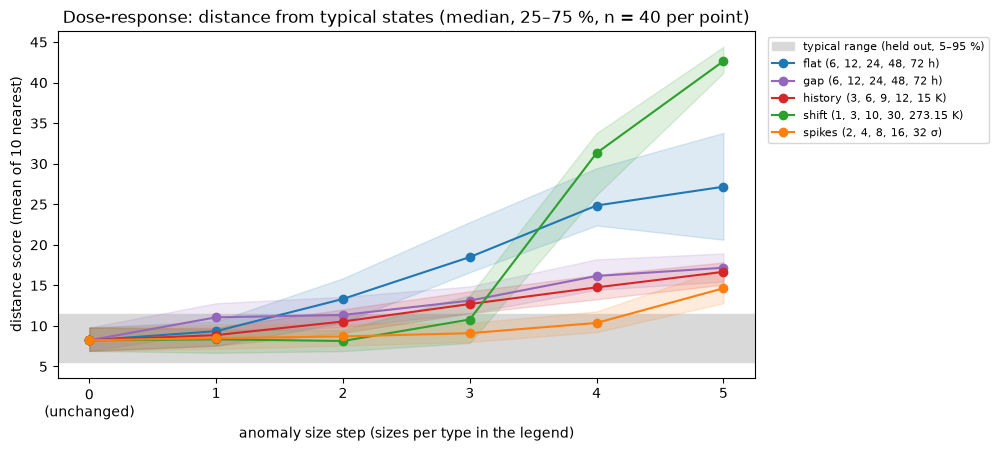

In [ ]:
# Dose-response: median score per size, one line per type; grey band = typical range
COL = {"flat": "tab:blue", "spikes": "tab:orange", "gap": "tab:purple", "shift": "tab:green", "history": "tab:red"}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhspan(TYP_LO, TYP_HI, color="0.85", label="typical range (held out, 5–95 %)")
for kind, d in dose.reset_index().groupby("kind"):
    sizes = ", ".join(f"{s:g}" for s in SIZES[kind][1:])
    ax.plot(d.step, d["median"], "o-", color=COL[kind], label=f"{kind} ({sizes} {UNITS[kind]})")
    ax.fill_between(d.step, d.q25, d.q75, color=COL[kind], alpha=0.15)
ax.set_xticks(range(6), ["0\n(unchanged)", "1", "2", "3", "4", "5"])
ax.set(
    xlabel="anomaly size step (sizes per type in the legend)",
    ylabel="distance score (mean of 10 nearest)",
    title=f"Dose-response: distance from typical states (median, 25–75 %, n = {dose.n.min()} per point)",
)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(RESULTS / "dose_response.png", dpi=150, bbox_inches="tight")

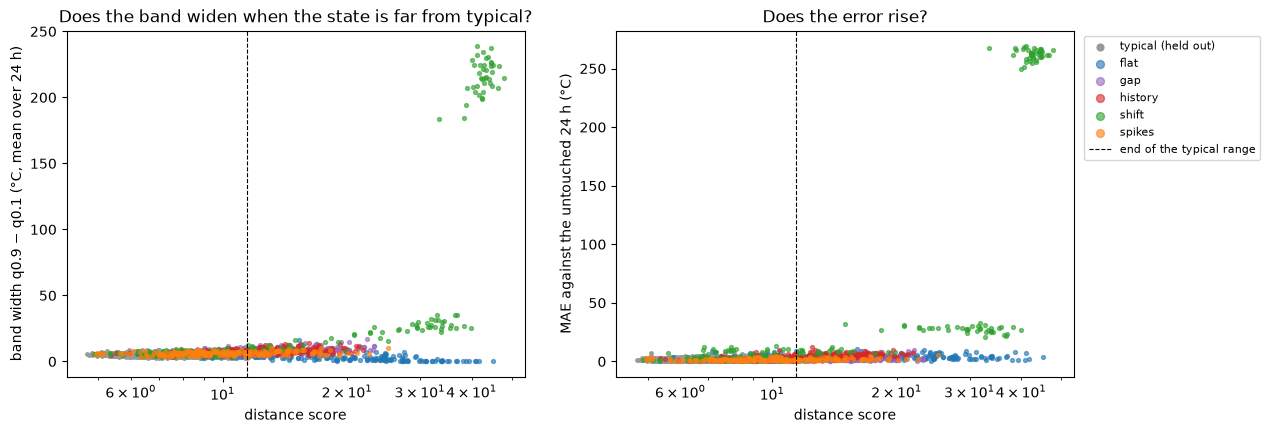

In [8]:
# ---- Score against band width (left) and against error (right), typical contexts in grey ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, (v, label) in zip(
    axes, [("band", "band width q0.9 − q0.1 (°C, mean over 24 h)"), ("mae", "MAE against the untouched 24 h (°C)")]
):
    ref_v = (
        (HELD_P[:, 8] - HELD_P[:, 0]).mean(1)
        if v == "band"
        else np.nanmean(
            np.abs(HELD_P[:, 4] - np.stack([OBSV[i : i + HORIZON, j] for i, j in zip(held.i, held.j)])), axis=1
        )
    )
    ax.scatter(held.score, ref_v, s=6, c="0.6", label="typical (held out)")
    for kind, d in anom[anom.step > 0].groupby("kind"):
        ax.scatter(d.score, d[v], s=8, c=COL[kind], alpha=0.6, label=kind)
    ax.axvline(TYP_HI, color="k", lw=0.8, ls="--", label="end of the typical range")
    ax.set(xlabel="distance score", ylabel=label, xscale="log")
axes[0].set_title("Does the band widen when the state is far from typical?")
axes[1].set_title("Does the error rise?")
axes[1].legend(fontsize=8, markerscale=2, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(RESULTS / "score_band_error.png", dpi=150, bbox_inches="tight")

## 8 · Results per hypothesis

The two techniques (sections 6 and 7) ran on all anomaly types and sizes. Here the results are read **one hypothesis at a
time**: [H1](#h1) → [H2](#h2) → [H3](#h3), after an overview.

### 8.0 · Overview: do the two techniques agree?

Per type: does the band change together with the state distance? The paired changes against size 0 of the same
reference case (Δ score, Δ band, Δ error) are compared by rank correlation. Reading:

| Δ score | Δ band | Δ error | Reading |
|---|---|---|---|
| up | up | up | knows |
| up | flat | up | sees it, does not show it in the band |
| flat | flat | up | fails silently, also inside |
| flat | flat | flat | the anomaly does not matter to the model (check that it really left the typical input range) |

In [ ]:
# Paired changes against size 0: correlation of the score with the band and with the error, per type
cmp = []
for kind, d in anom[anom.step > 0].groupby("kind"):
    cmp.append(
        {
            "kind": kind,
            "rho(Δscore, Δband)": spearmanr(d.d_score, d.d_band).statistic,
            "rho(Δscore, Δmae)": spearmanr(d.d_score, d.d_mae).statistic,
            "Δband / Δmae (largest size, median)": (
                d[d.step == 5].d_band / d[d.step == 5].d_mae.where(lambda s: s.abs() > 1e-6)
            ).median(),
        }
    )
cmp_table = pd.DataFrame(cmp).set_index("kind").round(3)
cmp_table

,"rho(Δscore, Δband)","rho(Δscore, Δmae)","Δband / Δmae (largest size, median)"
kind,,,
flat,-0.648,0.162,-1.752
gap,0.587,-0.031,1.058
history,0.574,0.643,0.711
shift,0.870,0.805,0.803
spikes,0.515,0.510,1.609


<a id="h1"></a>
### 8.1 · H1: does the state move away from the typical cloud?

*Evidence: the first size at which the median score leaves the typical range, and the dose-response table (Technique 1). Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [10]:
from IPython.display import display

# H1: from which size on does the median score leave the typical range, per anomaly type?
display(pd.Series(far, name="first size above the typical range").to_frame())
dose.round(3)

,first size above the typical range
flat,12.0
gap,24.0
history,9.0
shift,30.0
spikes,32.0


size   n  median     q25     q75  above_typical
kind    step                                                   
flat    0       0.00  40   8.231   6.926   9.802          0.025
        1       6.00  40   9.353   7.550  10.555          0.175
        2      12.00  40  13.328  10.422  15.871          0.600
        3      24.00  40  18.488  16.614  22.796          0.950
        4      48.00  40  24.846  22.380  29.442          1.000
        5      72.00  40  27.161  20.630  33.800          1.000
gap     0       0.00  40   8.231   6.926   9.802          0.025
        1       6.00  40  11.060   9.274  12.799          0.450
        2      12.00  40  11.350   9.839  13.592          0.475
        3      24.00  40  13.121  11.579  14.870          0.750
        4      48.00  40  16.161  14.448  18.202          0.925
        5      72.00  40  17.174  15.472  18.940          0.975
history 0       0.00  40   8.231   6.926   9.802          0.025
        1       3.00  40   8.869   7.571   9.781          0.100
        2       6.00  40  10.545   9.157  12.041          0.325
        3       9.00  40  12.701  11.555  14.266          0.800
        4      12.00  40  14.753  13.286  16.277          0.925
        5      15.00  40  16.664  15.098  17.830          1.000
shift   0       0.00  40   8.231   6.926   9.802          0.025
        1       1.00  40   8.346   6.684   9.552          0.050
        2       3.00  40   8.143   6.894   9.472          0.075
        3      10.00  40  10.792   7.906  13.772          0.475
        4      30.00  40  31.320  26.140  33.779          1.000
        5     273.15  40  42.644  41.188  44.408          1.000
spikes  0       0.00  40   8.231   6.926   9.802          0.025
        1       2.00  40   8.496   7.186  10.208          0.025
        2       4.00  40   8.705   7.562  10.215          0.100
        3       8.00  40   9.104   8.023  10.368          0.225
        4      16.00  40  10.371   9.236  11.787          0.325
        5      32.00  40  14.640  12.794  17.123          0.900

**Result:** The state reacts to every type, but only above a size that differs by type. The median score leaves the typical range (5.57 to 11.43) at 12 h for `flat`, 24 h for `gap`, 9 K for `history`, 30 K for `shift` and 32 σ for `spikes`. The control (size 0) stays inside: median 8.23, and 2.5 % of its cases lie above the range.

**Evidence:** the dose-response table and `dose_response.png`. For example `flat`: median score 8.23 at size 0, 13.33 at 12 h, 27.16 at 72 h; `shift`: 10.79 at 10 K, 31.32 at 30 K, 42.64 at 273 K; `spikes`: 10.37 at 16 σ (inside) and 14.64 at 32 σ.

**What it means:** A frozen sensor is noticed from 12 h, missing data from 24 h, a strange history from 9 K and an offset from 30 K; single spikes stay inside the typical range up to 16 σ. Open: only the state of the last block was read; other blocks may react at other sizes.

<a id="h2"></a>
### 8.2 · H2: does the band change with the anomaly?

*Evidence: the rank correlation between score and band width per type (with its bootstrap interval), and the change of the band at the largest size (Technique 2). Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [11]:
# H2: does the band widen when the state is far from typical? Correlation of score and band width, per type
t2[["rho_score_band", "band_ci", "largest size: d_band median"]].round(3)

,rho_score_band,band_ci,largest size: d_band median
kind,,,
flat,-0.690,-0.76 – -0.62,-4.649000
gap,0.526,0.44 – 0.62,3.919000
history,0.536,0.44 – 0.64,3.320000
shift,0.823,0.77 – 0.87,210.770004
spikes,0.262,0.12 – 0.42,0.955000


**Result:** The band moves with the score for all five types, but not in the same direction. It widens for `gap` (ρ = 0.53), `history` (0.54), `shift` (0.82) and, weakly, `spikes` (0.26). It narrows for `flat` (ρ = −0.69): the band falls from 5.80 at size 0 to 0.64 at 72 h.

**Evidence:** the table above (95 % intervals of ρ: flat −0.76 to −0.62, gap 0.44 to 0.62, history 0.44 to 0.64, shift 0.77 to 0.87, spikes 0.12 to 0.42) and the left panel of `score_band_error.png`. Change of the band at the largest size: flat −4.65, gap +3.92, history +3.32, shift +210.8, spikes +0.96.

**What it means:** A widening band does not always keep up with the error: for `history` the band grows by 3.3 while the error grows by 5.7. In Phase I (Exp 6) the band was widest for medium drops and narrower again for big or many drops. Exp 6 spread 1 to 16 drops of 3 to 15 °C over a 10-week history, and the drops followed the average cold front (slow recovery). Here three short drops (18 h each) sit in the last 72 h of a 4-week context. The sizes are the same, but the number, length and position of the drops differ, so the two results are not directly comparable. In our setup the `history` band keeps growing up to 15 K (5.80, 6.36, 7.14, 7.74, 8.47, 9.04).

<a id="h3"></a>
### 8.3 · H3: does the error change while the band does not?

*Evidence: where the error rises with the score but the band does not (the overview table in 8.0 and the right panel of `score_band_error.png`). Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [12]:
# H3: does the error rise while the band stays flat? Correlation of score and error, and the change of the error at the largest size
display(t2[["rho_score_mae", "mae_ci", "d_mae median"]].round(3))
cmp_table

,rho_score_mae,mae_ci,d_mae median
kind,,,
flat,0.365,0.28 – 0.45,2.713000
gap,0.200,0.06 – 0.35,0.826000
history,0.673,0.60 – 0.75,5.741000
shift,0.796,0.76 – 0.83,260.871002
spikes,0.222,0.06 – 0.38,0.388000


,"rho(Δscore, Δband)","rho(Δscore, Δmae)","Δband / Δmae (largest size, median)"
kind,,,
flat,-0.648,0.162,-1.752
gap,0.587,-0.031,1.058
history,0.574,0.643,0.711
shift,0.870,0.805,0.803
spikes,0.515,0.510,1.609


**Result:** Only one type shows a clear case of an error that rises while the band does not: `flat`. At 72 h its error is 2.71 higher than at size 0 and its band is 4.65 narrower. For `gap` and `spikes` the band changes at least as much as the error, and for `history` and `shift` it follows the error only in part. The effects of `spikes` are small.

**Evidence:** the tables above and the right panel of `score_band_error.png`. Ratio of the change of the band to the change of the error at the largest size: flat −1.75, gap 1.06, history 0.71, shift 0.80, spikes 1.61. Rank correlation of score and error: flat 0.37, gap 0.20, history 0.67, shift 0.80, spikes 0.22.

**What it means:** A frozen sensor is the clearest case in which the error rises without the band: the band gets narrower the longer the input is frozen (5.80 at size 0, 0.64 at 72 h). Open: for `history` the ratio of 0.71 means that the band follows the error only partly; `spikes` and `gap` change the error so little that "silent" is hard to tell.

## 9 · Checks

*Does the result hold on other dates, other points, other groups? What did we try to break it with?*

1. **Size 0 is the baseline:** for every type, size 0 gives the same state as the unchanged context, so the same score as
   the held-out case, and the forecast of the unchanged context matches the Phase I forecast in `tirex2_forecasts.npz`.
2. **Held-out against reference:** the score of the held-out typical contexts is compared with the leave-one-out score
   of the reference contexts. They differ (median 7.94 against 6.54, KS statistic 0.34), see section 11. The typical
   range is taken from the held-out contexts, which is the more careful choice.
3. **Same reference cases for every type:** every type and size uses the same `N_BASE` contexts.
4. **Enough cases:** at least 30 reference cases per size; the spread (25–75 %) is reported, not single cases.
5. **Band width is meaningful:** `tirex-2==0.3.1` does not sort the quantiles (`main` does), so crossed q0.1 / q0.9 would
   make the band width negative; their share is printed.

In [ ]:
from scipy.stats import ks_2samp

# 1 size 0 is the baseline: same state and same forecast as the unchanged context
z = anom[anom.step == 0]
held_score = held.set_index(["i", "pid"]).score
assert np.allclose(z.score, held_score.loc[list(zip(z.i, z.pid))].to_numpy(), atol=1e-4)
# the same context gives the same state in every type; not bit-for-bit, because the batches differ (float noise, below 1e-3)
assert all(np.allclose(ANOM_S[z[z.kind == k].index], ANOM_S[z[z.kind == "flat"].index], atol=1e-3) for k in SIZES)
preds_p1 = P1["preds"]  # read the array from the file once, not once per case
p1 = np.stack([preds_p1[k, p1_col[p]] for k, p in zip(z.p1_k, z.pid)]).astype(np.float32)
print(f"size 0 vs Phase I forecast: max |diff| {np.abs(ANOM_P[z.index] - p1).max():.4f} °C")
assert np.abs(ANOM_P[z.index] - p1).max() < 0.05

# 2 the held-out contexts sit inside the typical cloud
ks = ks_2samp(held.score, ref.score)
print(
    f"held-out score median {held.score.median():.2f} vs reference leave-one-out {ref.score.median():.2f};"
    f" KS statistic {ks.statistic:.3f} (p = {ks.pvalue:.3f})"
)

# 3 same reference cases for every type and size, 4 enough cases
per = anom.groupby(["kind", "step"]).base.apply(lambda s: tuple(sorted(s)))
assert per.nunique() == 1 and len(per.iloc[0]) >= 30, "types or sizes use different (or too few) reference cases"
print(f"every type and size: the same {len(per.iloc[0])} reference cases")

# tirex-2 0.3.1 does not sort the quantiles (main does); how often do q0.1 and q0.9 cross?
print(f"cases with q0.9 < q0.1 somewhere in the 24 h: {(ANOM_P[:, 8] < ANOM_P[:, 0]).any(axis=1).mean():.1%}")

size 0 vs Phase I forecast: max |diff| 0.0156 °C
held-out score median 7.94 vs reference leave-one-out 6.54; KS statistic 0.343 (p = 0.000)
every type and size: the same 40 reference cases
cases with q0.9 < q0.1 somewhere in the 24 h: 0.0%


## 10 · What it means

**Answer to the question.** The state reacts to every type of anomaly we tried, but only above a size that depends on the type: a frozen sensor from 12 h, a gap from 24 h, a strange history from 9 K, an offset from 30 K and a spike only at 32 σ. The band does not follow reliably. It widens for `gap`, `history`, `shift` and, weakly, `spikes`, but for a frozen sensor it narrows while the error rises (error +2.7, band −4.6 at 72 h).

Per anomaly type:
- **Does the state leave the typical range, and from which size on ("how far is far")?** *H1:* 12 h (`flat`), 24 h (`gap`), 9 K (`history`), 30 K (`shift`), 32 σ (`spikes`).
- **Does the band widen with the score, or only the error?** *H2, H3:* the band widens for four types and narrows for `flat`; only `flat` is a clear case of an error that rises without the band.
- **Link to Exp 6:** with three short drops in the last 72 h, the `history` band grows steadily up to 15 K and does not shrink for the largest drops, and the state is far from typical (score 16.7 against an upper limit of 11.4). Exp 6 used 1 to 16 drops spread over 10 weeks and found the band narrower again for big or many drops, so the results are not directly comparable.

**What is still open.**
- Only the last block was read; other blocks may react earlier (see "Further ideas").
- The held-out scores are higher than the reference scores (check 2); we did not look into why.
- 40 base contexts and one position of the anomaly (the last 72 h).

### Further ideas (not run)

Ideas for new experiments that follow from the setup above. None of them has been run yet; each one that is run would get its own hypothesis (H4, H5, …) and verdict cell in section 8.

| # | Idea | What it tests | What we would do |
|---|---|---|---|
| 1 | **Other blocks** | At which depth does an anomaly show up in the state? | Repeat the score with the state of earlier blocks, not only the last. |
| 2 | **Anomalies earlier in the context** | Does the position matter, or only the last hours? | Move the anomaly window from the last 72 h to earlier days. |
| 3 | **Combined anomalies** | Do two anomalies add up in the score? | Inject two types in the same context. |
| 4 | **Front starts as the base** | Is the score different when the underlying day is a front day? | Use front contexts (as in question D) as the base cases. |
| 5 | **Another distance** | Is the result an effect of the Euclidean distance? | Repeat with cosine distance and with a distance that uses the spread of the typical states (Mahalanobis). |

## 11 · What did not work

*Dead ends and negative results. They are part of the record.*

**1 · Spikes in absolute units**
- *Tried:* a fixed spike height (for example 0.5 K).
- *Happened:* it is inside the normal hour-to-hour change of many contexts, so the curve was flat for the wrong reason.
- *Did:* the sizes are in units of the context's own σ.

**2 · Shifting the whole context**
- *Tried:* an offset over all 672 h.
- *Happened:* the model scales every series by its own mean and spread, so the offset is removed before the first block.
- *Did:* the shift is applied to the last 72 h only.

**3 · Bit-for-bit equality of the size-0 states**
- *Tried:* a check that the unchanged context (size 0) gives exactly the same state in all five types.
- *Happened:* the check failed. The states differ by float noise (at most 6e-5 on a state scale of about 24; 35 to 37 of 40 rows exactly equal), because the batches are grouped differently.
- *Did:* the check uses a tolerance of 1e-3.

**4 · Held-out contexts against the reference**
- *Tried:* the held-out typical contexts expected to score like the leave-one-out reference contexts.
- *Happened:* they score higher (median 7.94 against 6.54, KS statistic 0.34).
- *Did:* the typical range is taken from the held-out contexts, the more careful choice. We did not look into the reason.

## AI usage in this notebook

Phase II of our pair is human-only. The professor allowed AI for formulating text and for code completion. In this notebook an AI model was used for the following, and for nothing else:

| What | How it was used |
|---|---|
| Code | Code completion while the notebook was written. Later, the code was commented and simplified with an assistant (named functions, block comments), and two things were fixed: the Phase I forecasts are read once instead of once per case, and an equality check on the size-0 states got a tolerance (section 11). |
| Wording | Suggestions for the neutral wording of the hypotheses, and drafts of the results in 8.1 to 8.3, of sections 10 and 11 and of the "Further ideas" cell. We checked the drafts against the outputs and edited them. |
| Structure | The notebook was ordered so that each hypothesis is answered in its own part (section 8), as in question F. |
| Run | The notebook was run in the project container from the command line (`nbconvert`), started by an assistant, and the outputs were stored in the notebook. |

The question, the hypotheses and the design of the experiment (anomaly types and sizes, the distance score, the control) are ours.